# 04 - Exploratory Data Analysis

## Objective

Perform exploratory data analysis on the cleaned e-commerce dataset to identify sales trends, product performance,
customer purchasing behaviour, regional patterns, and return trends.

## Data Source

Dataset/Cleaned/ecommerce_sales_customer_cleaned.csv

## Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Path

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
plot_dir = Path("../Screenshots/Plots")
plot_dir.mkdir(parents=True, exist_ok=True)

In [3]:
df = pd.read_csv(
    "../Dataset/Cleaned/ecommerce_sales_customer_cleaned.csv",
    parse_dates=[
        "OrderDate",
        "CustomerRegistrationDate",
        "ReturnDate"
    ]
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (49885, 18)


In [4]:
df.head()

,OrderID,OrderDate,CustomerID,CustomerRegistrationDate,ProductID,ProductName,Category,Quantity,UnitPrice,DiscountPct,GrossSales,DiscountAmount,NetSales,Region,Country,PaymentMethod,ReturnStatus,ReturnDate
0,ORD003508,2025-02-25,CUST07492,2024-07-08,P012,Kitchen Organizer,Home & Kitchen,4,33.21,0.0,132.84,0.00,132.84,Europe,Spain,Gift Card,Not Returned,NaT
1,ORD008536,2025-01-25,CUST06763,2022-08-07,P015,Water Bottle,Sports,3,17.01,20.0,51.03,10.21,40.82,Asia Pacific,India,Debit Card,Not Returned,NaT
2,ORD009501,2025-06-16,CUST07225,2023-06-30,P012,Kitchen Organizer,Home & Kitchen,5,35.11,0.0,175.55,0.00,175.55,Europe,Germany,Digital Wallet,Not Returned,NaT
3,ORD015712,2025-11-12,CUST04817,2024-08-18,P016,Face Moisturizer,Beauty,5,25.10,0.0,125.50,0.00,125.50,Latin America,Chile,Cash on Delivery,Not Returned,NaT
4,ORD003485,2025-02-04,CUST00134,2022-08-01,P003,Smart Watch,Electronics,1,110.82,10.0,110.82,11.08,99.74,Europe,Spain,Credit Card,Not Returned,NaT


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49885 entries, 0 to 49884
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   OrderID                   49885 non-null  object        
 1   OrderDate                 49885 non-null  datetime64[ns]
 2   CustomerID                49885 non-null  object        
 3   CustomerRegistrationDate  49885 non-null  datetime64[ns]
 4   ProductID                 49885 non-null  object        
 5   ProductName               49885 non-null  object        
 6   Category                  49885 non-null  object        
 7   Quantity                  49885 non-null  int64         
 8   UnitPrice                 49885 non-null  float64       
 9   DiscountPct               49885 non-null  float64       
 10  GrossSales                49885 non-null  float64       
 11  DiscountAmount            49885 non-null  float64       
 12  NetSales          

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
OrderID,49885,20745,ORD002630,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrderDate,49885,NaN,NaN,NaN,2025-03-30 15:21:23.183321856,2024-01-01 00:00:00,2024-08-15 00:00:00,2025-03-30 00:00:00,2025-11-11 00:00:00,2026-06-30 00:00:00,NaN
CustomerID,49885,6985,CUST01666,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerRegistrationDate,49885,NaN,NaN,NaN,2023-03-17 03:47:54.010223616,2021-04-11 00:00:00,2022-07-01 00:00:00,2023-03-13 00:00:00,2023-11-09 00:00:00,2026-04-06 00:00:00,NaN
ProductID,49885,20,P002,2638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProductName,49885,20,Bluetooth Speaker,2638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,49885,7,Electronics,9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,49885.0,NaN,NaN,NaN,3.004631,1.0,2.0,3.0,4.0,5.0,1.414681
UnitPrice,49885.0,NaN,NaN,NaN,37.841379,11.04,20.89,30.05,50.74,114.99,22.717726
DiscountPct,49885.0,NaN,NaN,NaN,8.676255,0.0,0.0,10.0,15.0,100.0,7.519869


In [7]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
ReturnDate,46703,93.62


In [8]:
print("First order date:", df["OrderDate"].min())
print("Last order date:", df["OrderDate"].max())

print(
    "Total days covered:",
    (df["OrderDate"].max() - df["OrderDate"].min()).days
)

First order date: 2024-01-01 00:00:00
Last order date: 2026-06-30 00:00:00
Total days covered: 911


In [9]:
return_summary = (
    df["ReturnStatus"]
    .value_counts()
    .to_frame("Record Count")
)

return_summary["Percentage"] = (
    return_summary["Record Count"] / len(df) * 100
).round(2)

return_summary

,Record Count,Percentage
ReturnStatus,,
Not Returned,46703,93.62
Returned,3182,6.38


## 2. Sales Performance Analysis

Analyse overall sales performance using key business metrics, including gross sales, net sales, discounts, units sold, order volume, and average order value.

In [10]:
total_orders = df["OrderID"].nunique()
total_customers = df["CustomerID"].nunique()

total_gross_sales = df["GrossSales"].sum()
total_discount = df["DiscountAmount"].sum()
total_net_sales = df["NetSales"].sum()

total_units_sold = df["Quantity"].sum()

average_order_value = total_net_sales / total_orders

sales_kpis = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Customers",
        "Total Gross Sales",
        "Total Discounts",
        "Total Net Sales",
        "Total Units Sold",
        "Average Order Value"
    ],
    "Value": [
        total_orders,
        total_customers,
        round(total_gross_sales, 2),
        round(total_discount, 2),
        round(total_net_sales, 2),
        total_units_sold,
        round(average_order_value, 2)
    ]
})

sales_kpis

,Metric,Value
0,Total Orders,20745.00
1,Total Customers,6985.00
2,Total Gross Sales,5680252.40
3,Total Discounts,493285.23
4,Total Net Sales,5186967.17
5,Total Units Sold,149886.00
6,Average Order Value,250.03


In [11]:
monthly_sales = (
    df.groupby(df["OrderDate"].dt.to_period("M"))
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Gross_Sales=("GrossSales", "sum"),
        Discount_Amount=("DiscountAmount", "sum"),
        Net_Sales=("NetSales", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

monthly_sales["OrderDate"] = (
    monthly_sales["OrderDate"].astype(str)
)

monthly_sales.head()

,OrderDate,Total_Orders,Gross_Sales,Discount_Amount,Net_Sales,Units_Sold
0,2024-01,719,194801.01,17171.62,177629.39,5125
1,2024-02,611,166830.49,14249.76,152580.73,4409
2,2024-03,708,195903.74,17415.13,178488.61,5211
3,2024-04,734,193967.97,17481.56,176486.41,5173
4,2024-05,685,190948.38,15649.80,175298.58,4930


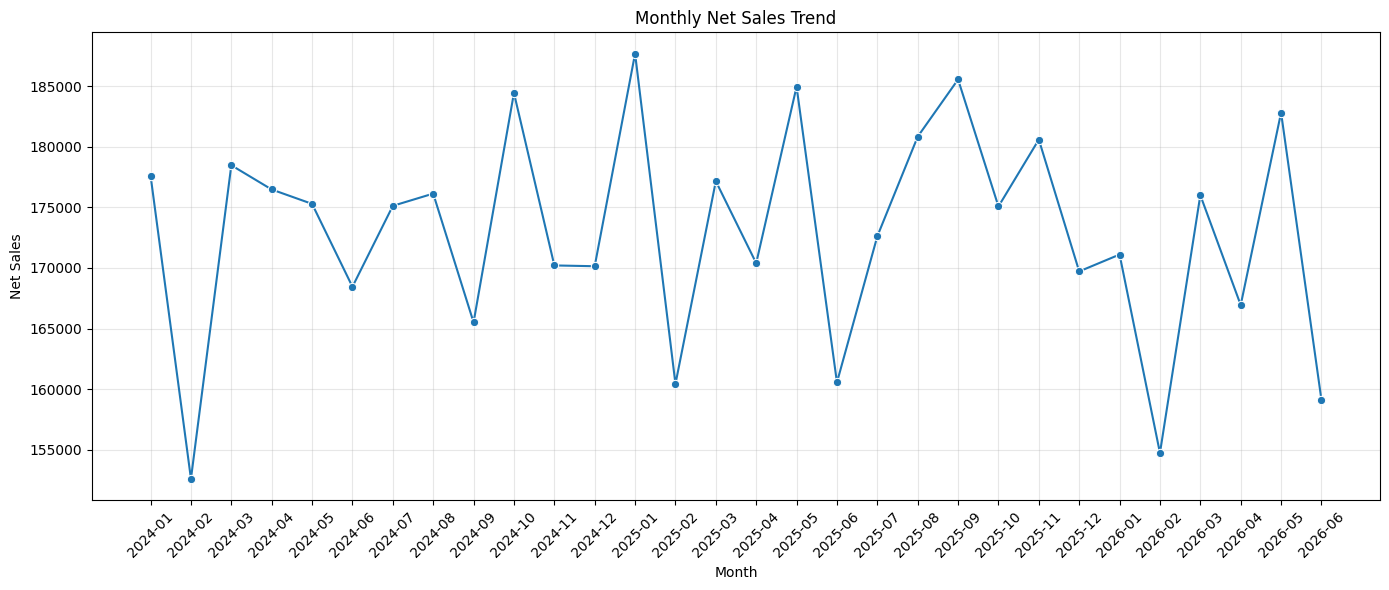

In [12]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="OrderDate",
    y="Net_Sales",
    marker="o"
)

plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    plot_dir / "01_monthly_net_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

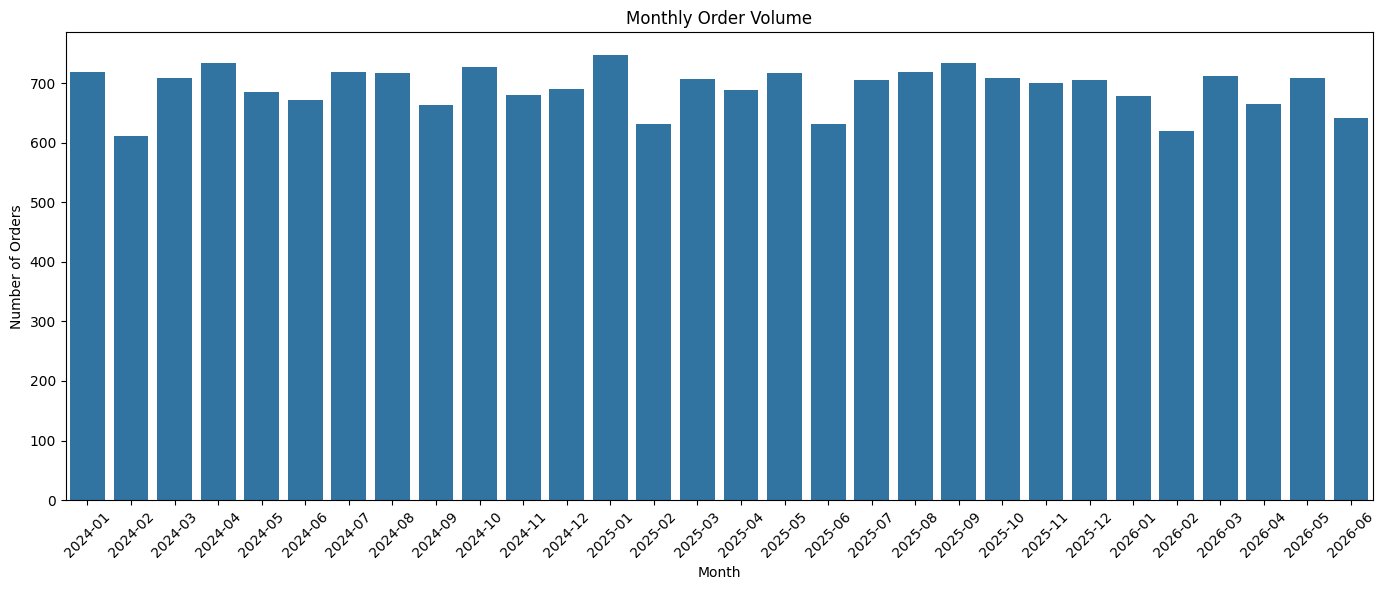

In [13]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=monthly_sales,
    x="OrderDate",
    y="Total_Orders"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    plot_dir / "02_monthly_order_volume.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
monthly_sales.sort_values(
    "Net_Sales",
    ascending=False
).head(10)

,OrderDate,Total_Orders,Gross_Sales,Discount_Amount,Net_Sales,Units_Sold
12,2025-01,748,205177.13,17461.58,187715.55,5456
20,2025-09,734,203331.73,17752.53,185579.20,5355
16,2025-05,717,202298.18,17313.81,184984.37,5260
9,2024-10,728,201512.56,17049.65,184462.91,5418
28,2026-05,708,201505.28,18668.84,182836.44,5212
19,2025-08,719,197927.95,17076.53,180851.42,5212
22,2025-11,700,197183.39,16570.80,180612.59,5173
2,2024-03,708,195903.74,17415.13,178488.61,5211
0,2024-01,719,194801.01,17171.62,177629.39,5125
14,2025-03,707,193604.36,16433.80,177170.56,5127


## 3. Product Performance Analysis

Analyse product and category performance to identify best-selling products, revenue-generating products, and category-level sales contributions.

The analysis will focus on units sold, order volume, gross sales, discounts, and net sales.

In [15]:
product_performance = (
    df.groupby(["ProductID", "ProductName", "Category"])
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Gross_Sales=("GrossSales", "sum"),
        Discount_Amount=("DiscountAmount", "sum"),
        Net_Sales=("NetSales", "sum")
    )
    .reset_index()
)

product_performance = product_performance.sort_values(
    "Net_Sales",
    ascending=False
)

product_performance

,ProductID,ProductName,Category,Total_Orders,Units_Sold,Gross_Sales,Discount_Amount,Net_Sales
2,P003,Smart Watch,Electronics,2345,7265,727936.20,62123.55,665812.65
7,P008,Running Shoes,Fashion,2399,7514,565354.31,50244.11,515110.20
6,P007,Travel Backpack,Accessories,2384,7493,487326.06,42452.42,444873.64
1,P002,Bluetooth Speaker,Electronics,2532,8049,484004.33,42649.28,441355.05
9,P010,Denim Jeans,Fashion,2405,7581,379208.19,33000.98,346207.21
0,P001,Wireless Earbuds,Electronics,2353,7369,368491.87,31576.95,336914.92
16,P017,Skincare Bundle,Beauty,2388,7458,335325.42,28788.92,306536.50
12,P013,Desk Lamp,Home & Kitchen,2420,7459,298219.94,26414.61,271805.33
11,P012,Kitchen Organizer,Home & Kitchen,2475,7637,267460.60,23223.23,244237.37
3,P004,USB-C Hub,Electronics,2378,7409,222107.38,19265.77,202841.61


In [16]:
top_products = product_performance.head(10)

top_products[
    ["ProductName", "Category", "Units_Sold", "Net_Sales"]
]

,ProductName,Category,Units_Sold,Net_Sales
2,Smart Watch,Electronics,7265,665812.65
7,Running Shoes,Fashion,7514,515110.20
6,Travel Backpack,Accessories,7493,444873.64
1,Bluetooth Speaker,Electronics,8049,441355.05
9,Denim Jeans,Fashion,7581,346207.21
0,Wireless Earbuds,Electronics,7369,336914.92
16,Skincare Bundle,Beauty,7458,306536.50
12,Desk Lamp,Home & Kitchen,7459,271805.33
11,Kitchen Organizer,Home & Kitchen,7637,244237.37
3,USB-C Hub,Electronics,7409,202841.61


In [17]:
top_selling_products = (
    product_performance
    .sort_values("Units_Sold", ascending=False)
    .head(10)
)

top_selling_products[
    ["ProductName", "Category", "Units_Sold", "Net_Sales"]
]

,ProductName,Category,Units_Sold,Net_Sales
1,Bluetooth Speaker,Electronics,8049,441355.05
11,Kitchen Organizer,Home & Kitchen,7637,244237.37
14,Water Bottle,Sports,7589,131594.33
15,Face Moisturizer,Beauty,7585,159303.18
9,Denim Jeans,Fashion,7581,346207.21
10,Ceramic Mug Set,Home & Kitchen,7550,172666.50
5,Laptop Sleeve,Accessories,7539,172150.97
4,Phone Case,Accessories,7526,102876.35
7,Running Shoes,Fashion,7514,515110.20
6,Travel Backpack,Accessories,7493,444873.64


In [18]:
category_performance = (
    df.groupby("Category")
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Gross_Sales=("GrossSales", "sum"),
        Discount_Amount=("DiscountAmount", "sum"),
        Net_Sales=("NetSales", "sum")
    )
    .reset_index()
    .sort_values("Net_Sales", ascending=False)
)

category_performance

,Category,Total_Orders,Units_Sold,Gross_Sales,Discount_Amount,Net_Sales
3,Electronics,8548,30092,1802539.78,155615.55,1646924.23
4,Fashion,6663,22434,1091461.26,96136.76,995324.50
0,Accessories,6667,22558,788731.97,68831.01,719900.96
5,Home & Kitchen,6733,22646,754293.68,65584.48,688709.20
1,Beauty,4605,15043,509638.46,43798.78,465839.68
2,Books,6596,22246,371318.78,32243.41,339075.37
6,Sports,4599,14867,362268.47,31075.24,331193.23


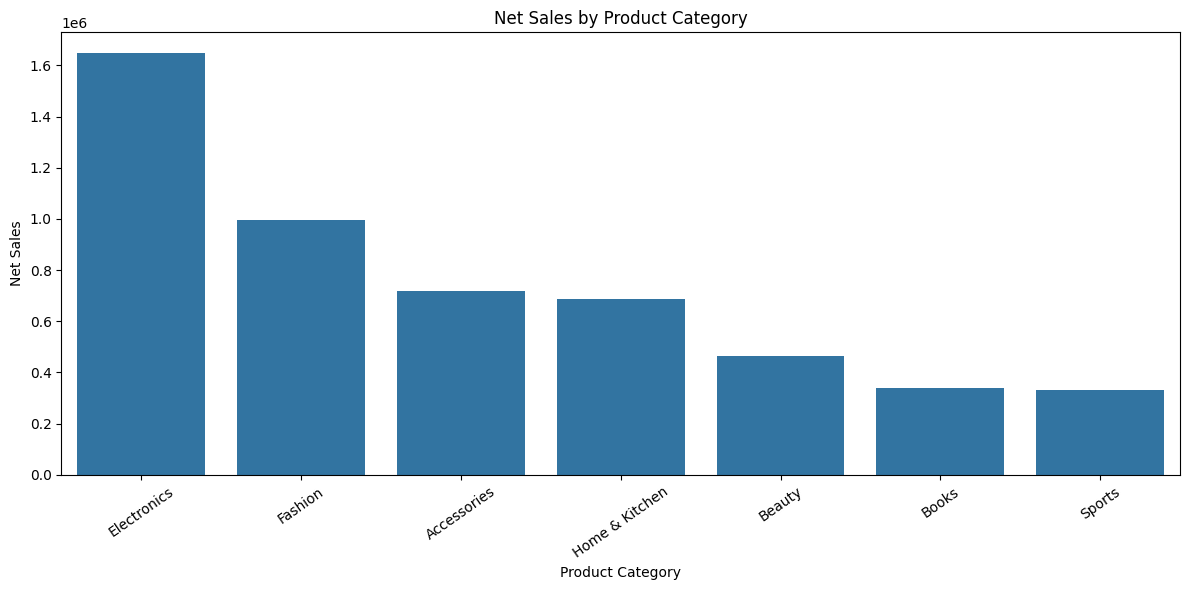

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_performance,
    x="Category",
    y="Net_Sales"
)

plt.title("Net Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Net Sales")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(
    plot_dir / "03_category_net_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

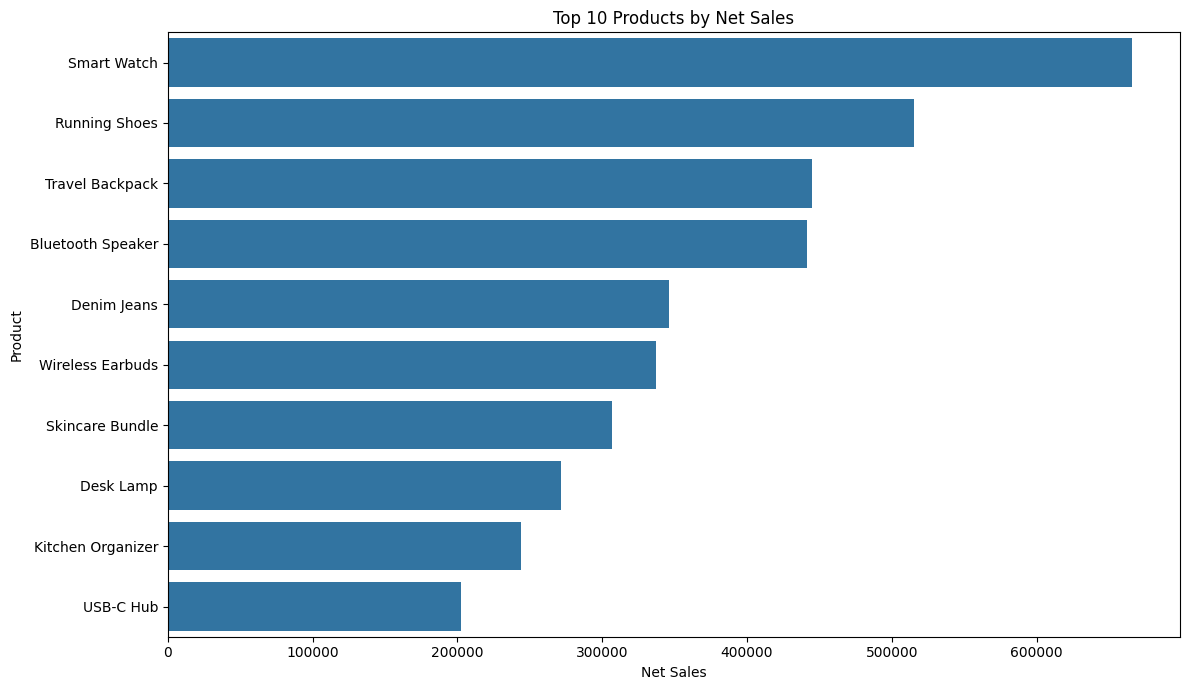

In [20]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Net_Sales",
    y="ProductName"
)

plt.title("Top 10 Products by Net Sales")
plt.xlabel("Net Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(
    plot_dir / "04_top_10_products_by_net_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

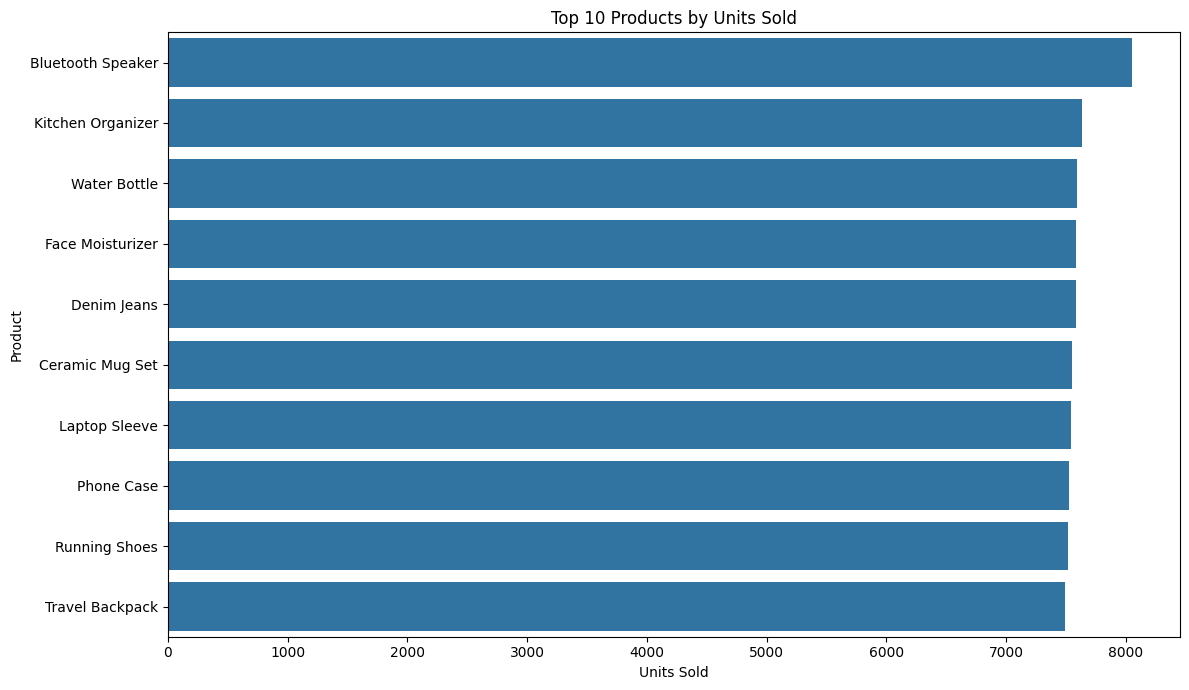

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_selling_products,
    x="Units_Sold",
    y="ProductName"
)

plt.title("Top 10 Products by Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    plot_dir / "05_top_10_products_by_units_sold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Customer Behaviour Analysis

Analyse customer purchasing behaviour to understand customer contributions, purchasing frequency, repeat purchases, and historical spending patterns.

The analysis will focus on customer-level order activity, total spending, average order value, and customer revenue contribution.

In [22]:
customer_performance = (
    df.groupby("CustomerID")
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Total_Transactions=("OrderID", "count"),
        Total_Units_Purchased=("Quantity", "sum"),
        Total_Gross_Sales=("GrossSales", "sum"),
        Total_Discounts=("DiscountAmount", "sum"),
        Total_Net_Sales=("NetSales", "sum"),
        First_Order_Date=("OrderDate", "min"),
        Last_Order_Date=("OrderDate", "max")
    )
    .reset_index()
)

customer_performance["Average_Order_Value"] = (
    customer_performance["Total_Net_Sales"] /
    customer_performance["Total_Orders"]
)

customer_performance.head()

,CustomerID,Total_Orders,Total_Transactions,Total_Units_Purchased,Total_Gross_Sales,Total_Discounts,Total_Net_Sales,First_Order_Date,Last_Order_Date,Average_Order_Value
0,CUST00001,4,9,17,485.69,36.64,449.05,2024-01-03,2025-04-02,112.262500
1,CUST00002,3,8,18,946.53,67.73,878.80,2024-03-12,2025-03-30,292.933333
2,CUST00003,2,4,7,193.04,11.55,181.49,2024-01-29,2026-01-01,90.745000
3,CUST00004,2,6,17,585.85,46.85,539.00,2024-02-27,2024-11-14,269.500000
4,CUST00005,4,11,38,1111.75,122.45,989.30,2024-10-18,2026-01-29,247.325000


In [23]:
purchase_frequency = (
    customer_performance["Total_Orders"]
    .value_counts()
    .sort_index()
    .reset_index()
)

purchase_frequency.columns = [
    "Number_of_Orders",
    "Number_of_Customers"
]

purchase_frequency

,Number_of_Orders,Number_of_Customers
0,1,1273
1,2,1791
2,3,1649
3,4,1155
4,5,656
5,6,279
6,7,118
7,8,41
8,9,15
9,10,8


In [24]:
total_customers = customer_performance["CustomerID"].nunique()

repeat_customers = (
    customer_performance[
        customer_performance["Total_Orders"] > 1
    ]["CustomerID"].nunique()
)

one_time_customers = total_customers - repeat_customers

repeat_customer_summary = pd.DataFrame({
    "Customer Type": [
        "Repeat Customers",
        "One-Time Customers"
    ],
    "Customer Count": [
        repeat_customers,
        one_time_customers
    ]
})

repeat_customer_summary["Percentage"] = (
    repeat_customer_summary["Customer Count"] /
    total_customers * 100
).round(2)

repeat_customer_summary

,Customer Type,Customer Count,Percentage
0,Repeat Customers,5712,81.78
1,One-Time Customers,1273,18.22


In [25]:
top_customers = (
    customer_performance
    .sort_values("Total_Net_Sales", ascending=False)
    .head(10)
)

top_customers[
    [
        "CustomerID",
        "Total_Orders",
        "Total_Units_Purchased",
        "Total_Net_Sales",
        "Average_Order_Value"
    ]
]

,CustomerID,Total_Orders,Total_Units_Purchased,Total_Net_Sales,Average_Order_Value
6194,CUST06644,10,84,3188.62,318.862000
40,CUST00044,9,83,3061.19,340.132222
1663,CUST01783,10,86,2920.96,292.096000
1582,CUST01696,9,59,2880.23,320.025556
1555,CUST01666,10,83,2823.78,282.378000
6765,CUST07258,10,84,2775.86,277.586000
4662,CUST05009,8,65,2681.98,335.247500
4773,CUST05125,7,61,2645.15,377.878571
2848,CUST03048,8,68,2638.00,329.750000
1688,CUST01808,9,60,2600.44,288.937778


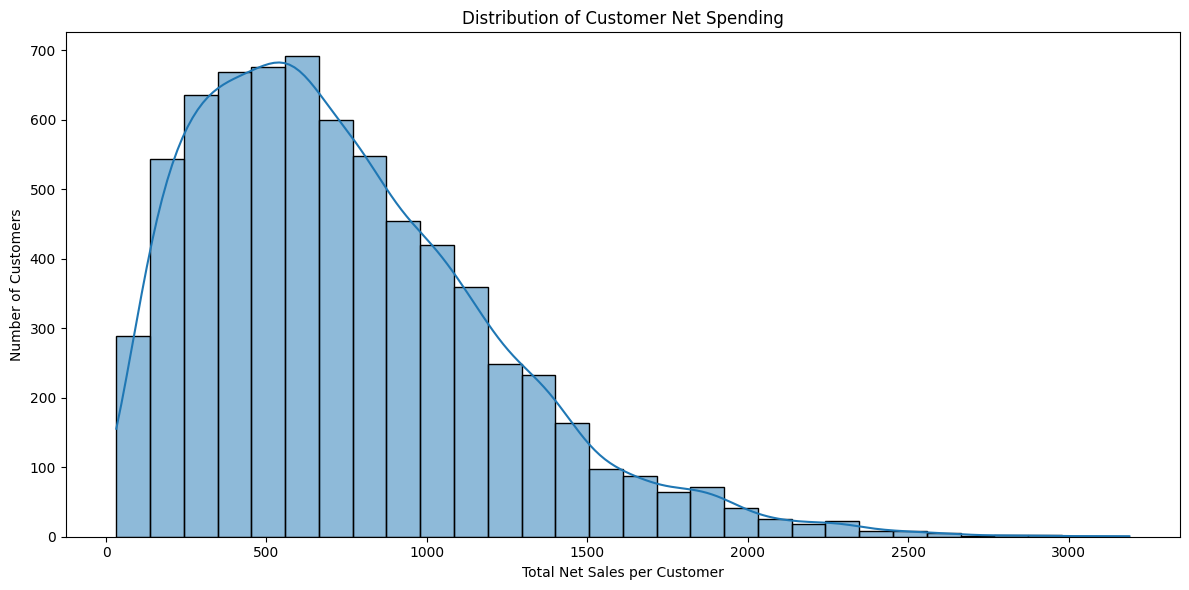

In [26]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=customer_performance,
    x="Total_Net_Sales",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Net Spending")
plt.xlabel("Total Net Sales per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    plot_dir / "06_customer_spending_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

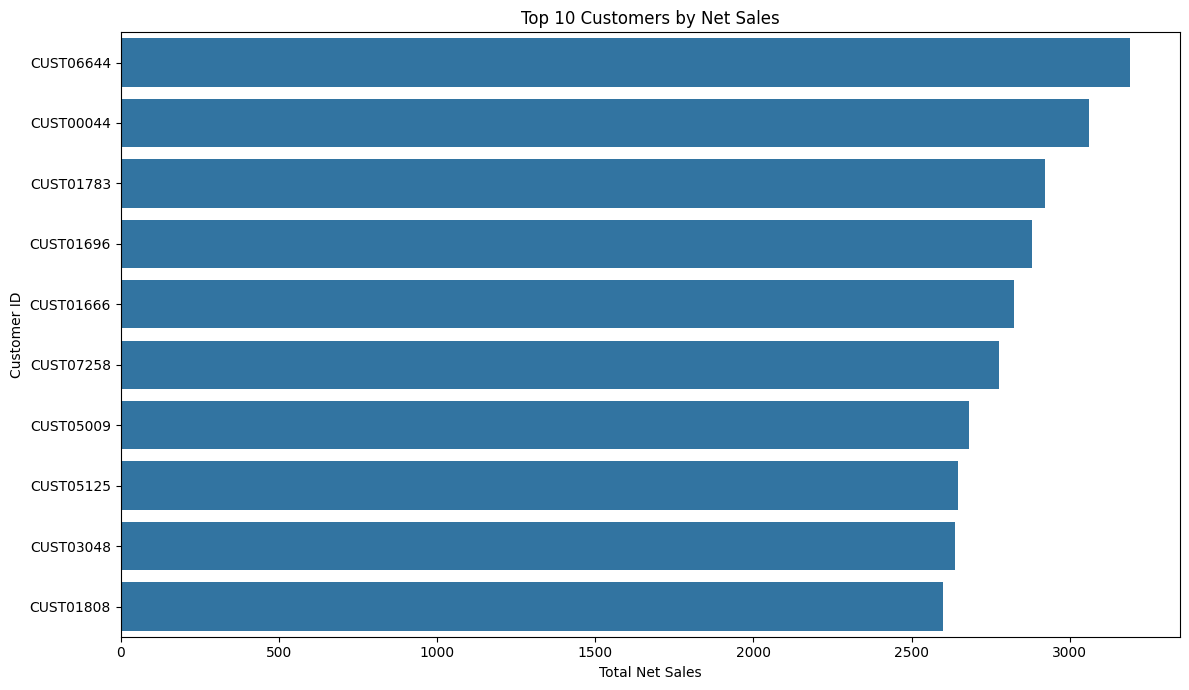

In [27]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_customers,
    x="Total_Net_Sales",
    y="CustomerID"
)

plt.title("Top 10 Customers by Net Sales")
plt.xlabel("Total Net Sales")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.savefig(
    plot_dir / "07_top_10_customers_by_net_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Regional & Payment Analysis

Analyse geographical sales performance and payment preferences to identify high-performing countries, regional contributions, and customer payment behaviour.

The analysis will focus on orders, units sold, net sales, and payment method distribution.

In [28]:
country_performance = (
    df.groupby(["Country", "Region"])
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Total_Customers=("CustomerID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Gross_Sales=("GrossSales", "sum"),
        Discount_Amount=("DiscountAmount", "sum"),
        Net_Sales=("NetSales", "sum")
    )
    .reset_index()
    .sort_values("Net_Sales", ascending=False)
)

country_performance

,Country,Region,Total_Orders,Total_Customers,Units_Sold,Gross_Sales,Discount_Amount,Net_Sales
11,Singapore,Asia Pacific,1287,1165,9258,350614.88,30182.80,320432.08
0,Australia,Asia Pacific,1267,1174,9205,347043.37,29742.28,317301.09
9,Pakistan,Middle East,1250,1155,9066,342929.12,29545.65,313383.47
8,Mexico,Latin America,1244,1137,9102,340183.28,28928.70,311254.58
2,Canada,North America,1256,1140,8980,340957.06,30289.46,310667.60
7,Japan,Asia Pacific,1222,1135,8814,336838.19,28811.67,308026.52
15,United Kingdom,Europe,1238,1142,8858,336876.79,29732.33,307144.46
16,United States,North America,1229,1135,8935,335254.35,29281.27,305973.08
6,India,Asia Pacific,1227,1120,8885,336194.23,30245.91,305948.32
3,Chile,Latin America,1231,1146,8854,332479.12,28901.78,303577.34


In [29]:
regional_performance = (
    df.groupby("Region")
    .agg(
        Total_Orders=("OrderID", "nunique"),
        Total_Customers=("CustomerID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Net_Sales=("NetSales", "sum")
    )
    .reset_index()
    .sort_values("Net_Sales", ascending=False)
)

regional_performance

,Region,Total_Orders,Total_Customers,Units_Sold,Net_Sales
1,Asia Pacific,5003,3635,36162,1251708.01
2,Europe,4774,3528,34571,1193854.61
4,Middle East,3615,2859,26145,915790.84
3,Latin America,3668,2903,26468,911432.99
5,North America,2485,2086,17915,616640.68
0,Africa,1200,1105,8625,297540.04


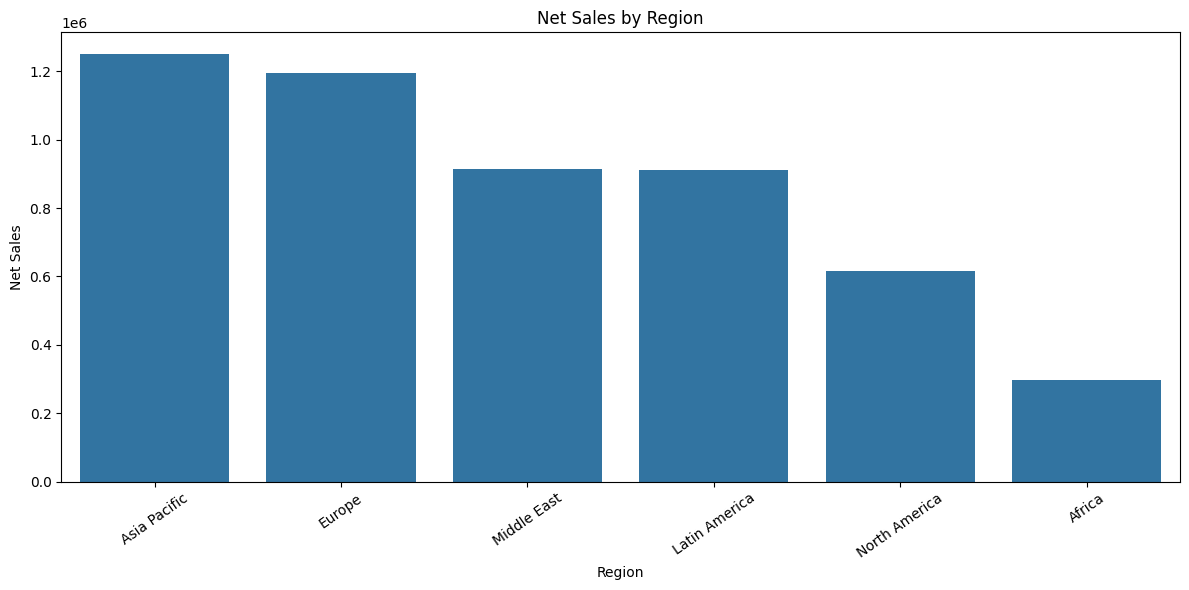

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=regional_performance,
    x="Region",
    y="Net_Sales"
)

plt.title("Net Sales by Region")
plt.xlabel("Region")
plt.ylabel("Net Sales")
plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    plot_dir / "08_net_sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

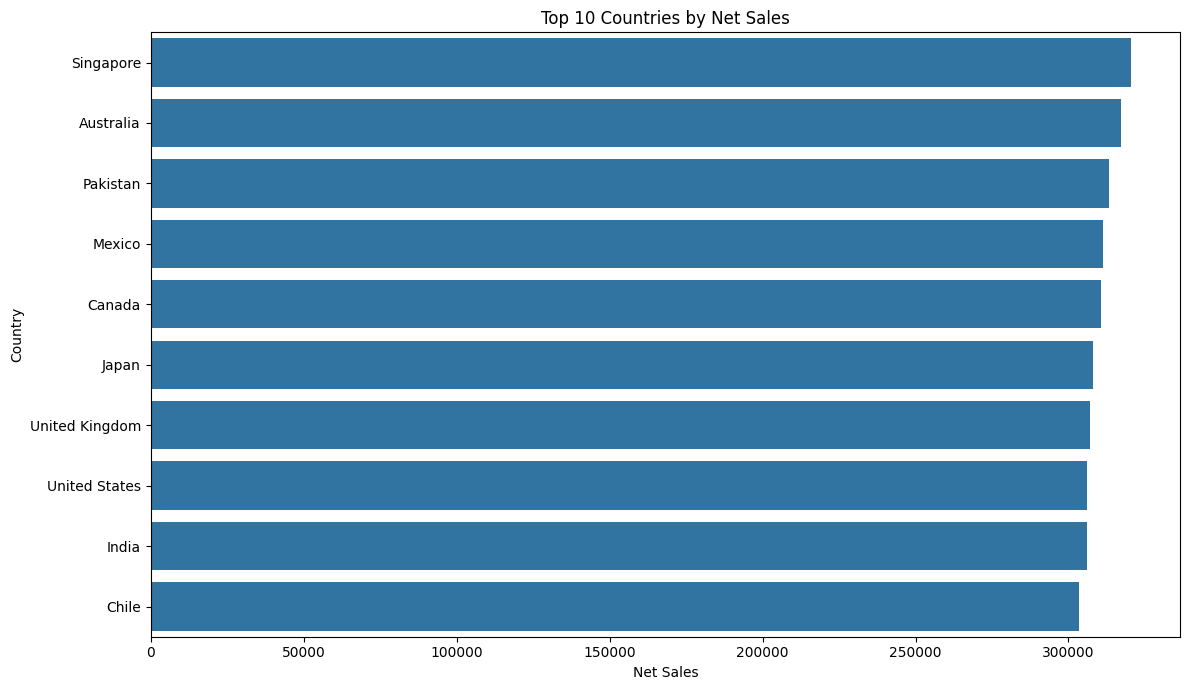

In [31]:
top_countries = (
    country_performance
    .sort_values("Net_Sales", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_countries,
    x="Net_Sales",
    y="Country"
)

plt.title("Top 10 Countries by Net Sales")
plt.xlabel("Net Sales")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    plot_dir / "09_top_10_countries_by_net_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
payment_performance = (
    df.groupby("PaymentMethod")
    .agg(
        Total_Line_Items=("OrderID", "count"),
        Net_Sales=("NetSales", "sum"),
        Total_Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Net_Sales", ascending=False)
)

payment_performance["Sales_Contribution_Pct"] = (
    payment_performance["Net_Sales"] /
    payment_performance["Net_Sales"].sum() * 100
).round(2)

payment_performance

,PaymentMethod,Total_Line_Items,Net_Sales,Total_Units_Sold,Sales_Contribution_Pct
1,Cash on Delivery,7186,753526.05,21613,14.53
4,Digital Wallet,7073,749551.52,21311,14.45
2,Credit Card,7156,743531.77,21637,14.33
0,Bank Transfer,7131,742115.93,21473,14.31
6,PayPal,7144,738290.11,21475,14.23
5,Gift Card,7109,735099.25,21206,14.17
3,Debit Card,7007,716384.16,20924,13.81
7,Unknown,79,8468.38,247,0.16


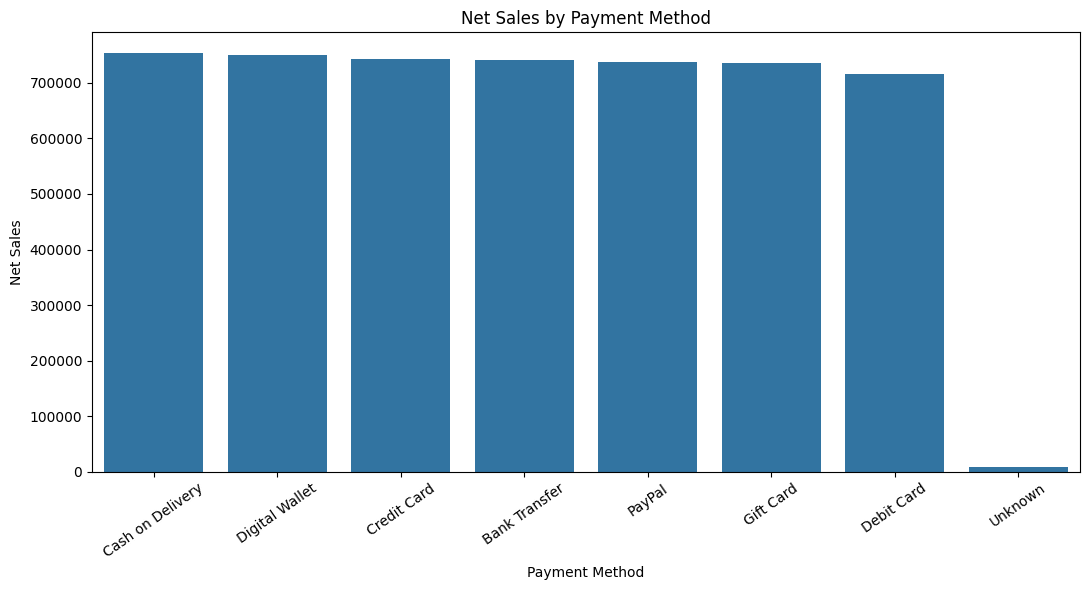

In [33]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=payment_performance,
    x="PaymentMethod",
    y="Net_Sales"
)

plt.title("Net Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Net Sales")
plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    plot_dir / "10_net_sales_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
payment_methods_per_order = (
    df.groupby("OrderID")["PaymentMethod"].nunique()
)

print(
    "Orders with multiple payment methods:",
    (payment_methods_per_order > 1).sum()
)

print(
    "Maximum payment methods per order:",
    payment_methods_per_order.max()
)

Orders with multiple payment methods: 18729
Maximum payment methods per order: 3


## 6. Returns Analysis

Analyse product returns to understand return patterns, return rates, and their relationship with product categories
and geographical regions.

The analysis will focus on returned transactions, return rates by category and country, and return trends over time.

In [35]:
return_performance = (
    df.groupby("ReturnStatus")
    .agg(
        Total_Records=("OrderID", "count"),
        Total_Orders=("OrderID", "nunique"),
        Total_Units=("Quantity", "sum"),
        Net_Sales=("NetSales", "sum")
    )
    .reset_index()
)

return_performance["Record_Percentage"] = (
    return_performance["Total_Records"] /
    return_performance["Total_Records"].sum() * 100
).round(2)

return_performance

,ReturnStatus,Total_Records,Total_Orders,Total_Units,Net_Sales,Record_Percentage
0,Not Returned,46703,20685,140280,4851010.05,93.62
1,Returned,3182,3026,9606,335957.12,6.38


In [36]:
category_returns = (
    df.groupby("Category")
    .agg(
        Total_Records=("OrderID", "count"),
        Returned_Records=(
            "ReturnStatus",
            lambda x: (x == "Returned").sum()
        )
    )
    .reset_index()
)

category_returns["Return_Rate_Pct"] = (
    category_returns["Returned_Records"] /
    category_returns["Total_Records"] * 100
).round(2)

category_returns.sort_values(
    "Return_Rate_Pct",
    ascending=False
)

,Category,Total_Records,Returned_Records,Return_Rate_Pct
4,Fashion,7444,493,6.62
1,Beauty,5017,330,6.58
6,Sports,4944,319,6.45
5,Home & Kitchen,7592,484,6.38
2,Books,7412,466,6.29
3,Electronics,9998,625,6.25
0,Accessories,7478,465,6.22


In [37]:
country_returns = (
    df.groupby("Country")
    .agg(
        Total_Records=("OrderID", "count"),
        Returned_Records=(
            "ReturnStatus",
            lambda x: (x == "Returned").sum()
        )
    )
    .reset_index()
)

country_returns["Return_Rate_Pct"] = (
    country_returns["Returned_Records"] /
    country_returns["Total_Records"] * 100
).round(2)

country_returns.sort_values(
    "Return_Rate_Pct",
    ascending=False
)

,Country,Total_Records,Returned_Records,Return_Rate_Pct
6,India,2950,214,7.25
14,United Arab Emirates,2878,206,7.16
5,Germany,2794,194,6.94
13,Spain,2864,196,6.84
2,Canada,3020,200,6.62
12,South Africa,2895,186,6.42
7,Japan,2906,186,6.40
4,France,2853,182,6.38
0,Australia,3059,193,6.31
3,Chile,2939,185,6.29


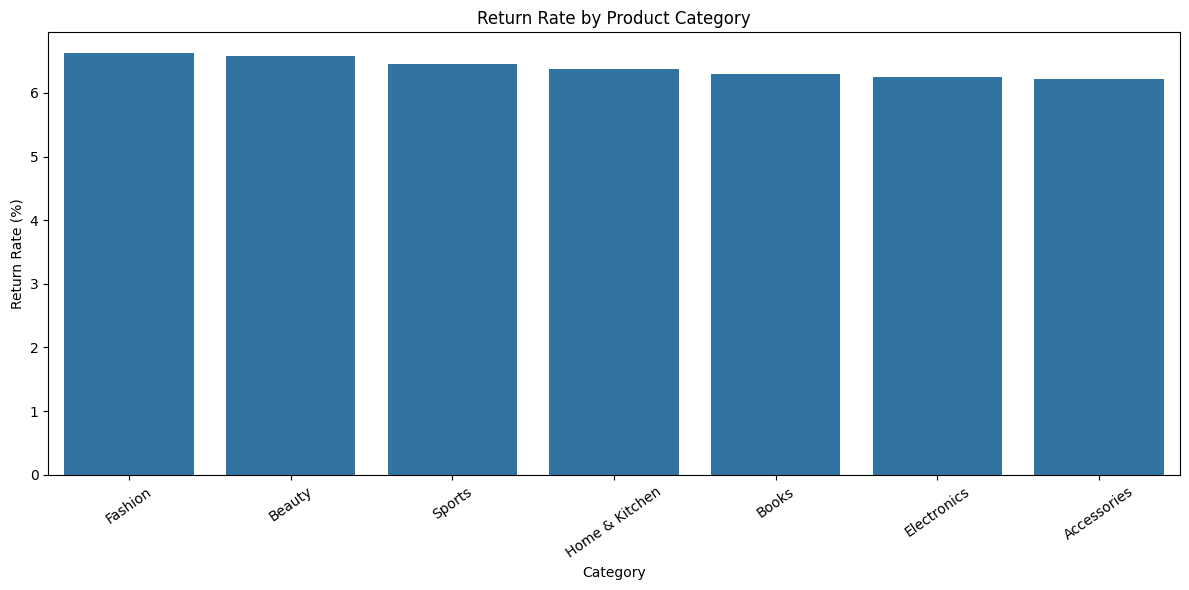

In [38]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_returns.sort_values(
        "Return_Rate_Pct",
        ascending=False
    ),
    x="Category",
    y="Return_Rate_Pct"
)

plt.title("Return Rate by Product Category")
plt.xlabel("Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    plot_dir / "11_return_rate_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

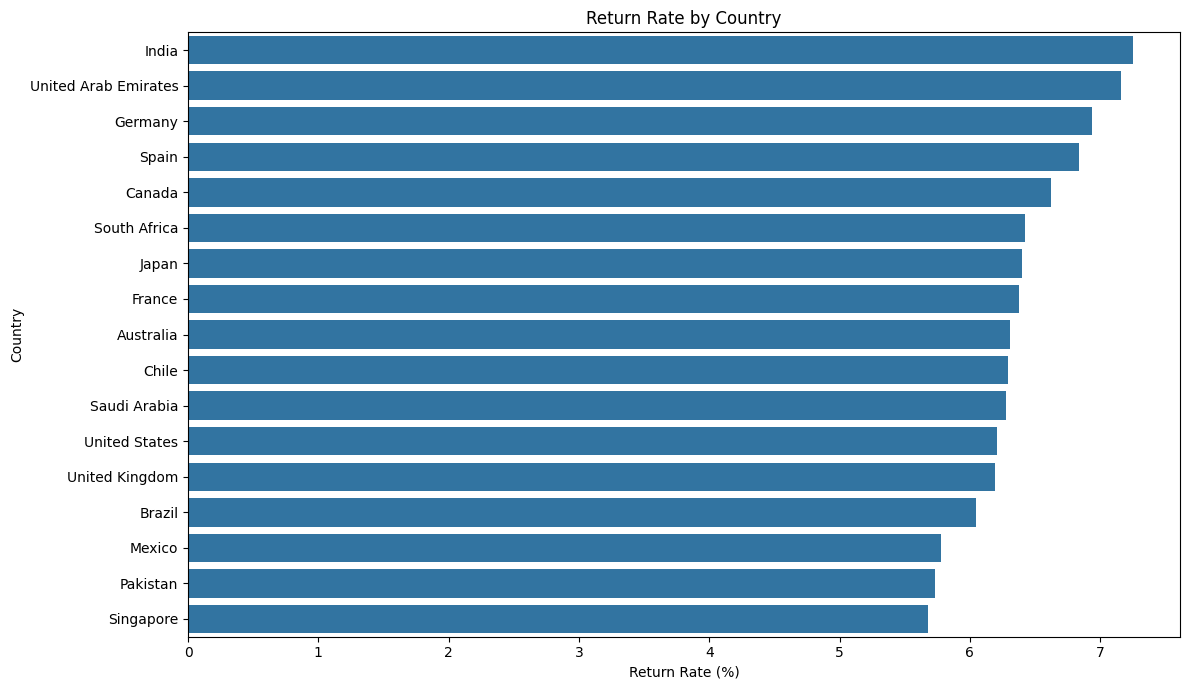

In [39]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_returns.sort_values(
        "Return_Rate_Pct",
        ascending=False
    ),
    x="Return_Rate_Pct",
    y="Country"
)

plt.title("Return Rate by Country")
plt.xlabel("Return Rate (%)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    plot_dir / "12_return_rate_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Key Findings & Business Insights

Summarise the major findings from the exploratory data analysis, highlighting sales performance, product and category contributions, customer purchasing behaviour, regional performance, payment patterns, and product returns.

The findings will be used to support subsequent SQL analysis, customer segmentation, and Power BI dashboard development.

In [40]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Customers",
        "Total Net Sales",
        "Total Units Sold",
        "Average Order Value",
        "Repeat Customer Rate",
        "Return Record Rate",
        "Top Performing Product",
        "Top Performing Category",
        "Top Performing Region",
        "Top Performing Country"
    ],
    "Result": [
        total_orders,
        total_customers,
        round(total_net_sales, 2),
        total_units_sold,
        round(average_order_value, 2),
        f"{repeat_customer_summary.loc[0, 'Percentage']}%",
        f"{return_performance.loc[return_performance['ReturnStatus'] == 'Returned', 'Record_Percentage'].iloc[0]}%",
        product_performance.iloc[0]["ProductName"],
        category_performance.iloc[0]["Category"],
        regional_performance.iloc[0]["Region"],
        country_performance.iloc[0]["Country"]
    ]
})

eda_summary

,Metric,Result
0,Total Orders,20745
1,Total Customers,6985
2,Total Net Sales,5186967.17
3,Total Units Sold,149886
4,Average Order Value,250.03
5,Repeat Customer Rate,81.78%
6,Return Record Rate,6.38%
7,Top Performing Product,Smart Watch
8,Top Performing Category,Electronics
9,Top Performing Region,Asia Pacific



### Key Business Insights

1. **Sales Performance:** The business generated 5.19 million in net sales across 20,745 distinct orders.

2. **Product Performance:** Smart Watch generated the highest product net sales, while Bluetooth Speaker recorded the highest unit sales.

3. **Category Performance:** Electronics was the leading category, generating approximately 1.65 million in net sales.

4. **Customer Behaviour:** Repeat customers represented 81.78% of the customer base, indicating substantial repeat purchasing activity during the observed period.

5. **Regional Performance:** Asia Pacific generated the highest regional net sales, while Singapore was the leading country.

6. **Payment Analysis:** Cash on Delivery recorded the highest net sales among the payment methods. Payment methods can overlap within an order, so these results represent transaction-level sales attribution.

7. **Returns:** Returned product records represented 6.38% of all product records. Fashion recorded the highest category return rate, while India had the highest country return rate.

### Conclusion

The exploratory analysis identified key patterns in sales performance, product contributions, customer purchasing behaviour, regional performance, payment methods, and product returns. These findings provide a foundation for further SQL analysis, customer segmentation, and Power BI dashboard development.
